# 05 · Decision Trees & Ensembles (Random Forest, AdaBoost, Gradient Boosting)

On spreadsheet-style ("tabular") data, tree ensembles — Random Forests and gradient boosting (XGBoost, LightGBM, CatBoost) — are usually the strongest models, beating neural networks in most industry settings.

**What you'll learn**
1. How a decision tree asks questions, and how it picks the *best* question (**Gini impurity**, **entropy**, **information gain**)
2. Building a full tree 🐍 in pure Python, 🔢 with NumPy, and 📦 in scikit-learn
3. Why single trees overfit, and how to stop them
4. **Bagging & Random Forests:** many trees voting
5. **Boosting:** trees that fix each other's mistakes — AdaBoost and **gradient boosting** from scratch

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math, random
from collections import Counter
plt.rcParams["figure.figsize"] = (5.5, 3.6)
plt.rcParams["axes.grid"] = True; plt.rcParams["grid.alpha"] = 0.3
rng = np.random.default_rng(0)

def plot_boundary(predict, X, y, ax=None, title="", h=200):
    ax = ax or plt.gca()
    x0, x1 = np.meshgrid(np.linspace(X[:, 0].min() - .5, X[:, 0].max() + .5, h),
                         np.linspace(X[:, 1].min() - .5, X[:, 1].max() + .5, h))
    Z = np.asarray(predict(np.c_[x0.ravel(), x1.ravel()])).reshape(x0.shape)
    ax.contourf(x0, x1, Z, alpha=0.3, cmap="coolwarm")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k", s=15); ax.set_title(title)

## 1. Intuition: a game of 20 questions

A decision tree is a flowchart of yes/no questions:
```
Is petal length < 2.45 cm?
├── yes → setosa
└── no  → Is petal width < 1.75 cm?
          ├── yes → versicolor
          └── no  → virginica
```
Each **internal node** asks "is feature j < threshold t?". Each **leaf** gives an answer (the majority class, or the average value for regression).

The boundaries are always **axis-aligned rectangles** — trees slice the space with horizontal and vertical cuts.

**Why people love trees:** easy to explain, no feature scaling needed, handle mixed feature types, capture interactions ("if age > 60 AND smoker…") automatically.

## 2. How to choose a question: impurity

A good question splits the data into groups that are each as **pure** (single-class) as possible. Two common impurity measures for a node whose class proportions are $p_1, \dots, p_K$:

$$ \text{Gini} = 1 - \sum_k p_k^2 \qquad\qquad \text{Entropy} = -\sum_k p_k \log_2 p_k $$

Both are 0 for a pure node and largest for a 50/50 mix. **Gini** = the chance two randomly drawn items from the node have different labels. **Entropy** = average number of yes/no questions needed to identify a label.

The quality of a split = how much it **reduces** impurity (the **information gain**):
$$ \text{Gain} = I(\text{parent}) - \frac{n_L}{n} I(\text{left}) - \frac{n_R}{n} I(\text{right}) $$

Counter({'A': 10})              gini = 0.000   entropy = 0.000
Counter({'A': 5, 'B': 5})       gini = 0.500   entropy = 1.000
Counter({'A': 9, 'B': 1})       gini = 0.180   entropy = 0.469


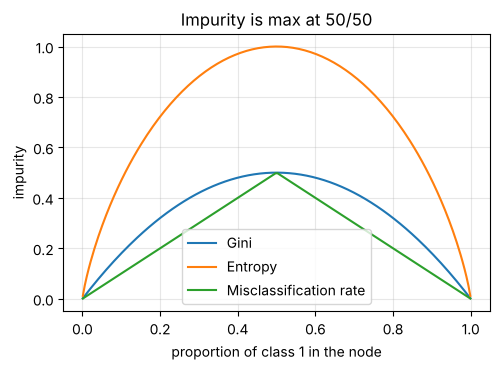

In [2]:
# 🐍 Pure Python impurity
def gini(labels):
    n = len(labels)
    return 1 - sum((c / n) ** 2 for c in Counter(labels).values())

def entropy(labels):
    n = len(labels)
    return -sum((c / n) * math.log2(c / n) for c in Counter(labels).values()) + 0.0  # +0.0 turns -0.0 into 0.0

for labels in [["A"] * 10, ["A"] * 5 + ["B"] * 5, ["A"] * 9 + ["B"]]:
    print(f"{Counter(labels)!s:30}  gini = {gini(labels):.3f}   entropy = {entropy(labels):.3f}")

p = np.linspace(0.001, 0.999, 200)
plt.plot(p, 1 - p**2 - (1 - p)**2, label="Gini"); plt.plot(p, -(p*np.log2(p) + (1-p)*np.log2(1-p)), label="Entropy")
plt.plot(p, 1 - np.maximum(p, 1-p), label="Misclassification rate")
plt.xlabel("proportion of class 1 in the node"); plt.ylabel("impurity"); plt.legend(); plt.title("Impurity is max at 50/50"); plt.show()

### Finding the best split
Try **every feature** and **every threshold** (midpoints between sorted unique values), and keep the one with the largest gain. That's a "greedy" search — the best question *right now*, without looking ahead.

In [3]:
# 🐍 Pure Python: best split search
def best_split_python(X, y, criterion=gini):
    best = {"gain": 0.0}
    parent = criterion(y)
    n, d = len(X), len(X[0])
    for j in range(d):
        values = sorted(set(row[j] for row in X))
        for lo, hi in zip(values, values[1:]):
            t = (lo + hi) / 2
            left = [yi for row, yi in zip(X, y) if row[j] < t]
            right = [yi for row, yi in zip(X, y) if row[j] >= t]
            gain = parent - len(left) / n * criterion(left) - len(right) / n * criterion(right)
            if gain > best["gain"]:
                best = {"gain": gain, "feature": j, "threshold": t}
    return best

from sklearn.datasets import load_iris
iris = load_iris(); Xi, yi = iris.data, iris.target
b = best_split_python(Xi.tolist(), yi.tolist())
print(f"best first question: is {iris.feature_names[b['feature']]} < {b['threshold']:.2f}?  (gain {b['gain']:.3f})")

best first question: is petal length (cm) < 2.45?  (gain 0.333)


## 3. Building the whole tree (recursion)

1. Find the best split for the current data.
2. Split it into left and right groups.
3. **Repeat on each group** (recursion).
4. Stop when a node is pure, too small, too deep, or no split helps — make it a **leaf**.

In [4]:
# 🐍 Pure Python decision tree — nodes are plain dicts
def build_tree_python(X, y, depth=0, max_depth=5, min_samples=2):
    majority = Counter(y).most_common(1)[0][0]
    if depth >= max_depth or len(set(y)) == 1 or len(y) < min_samples:
        return {"leaf": majority}
    split = best_split_python(X, y)
    if split["gain"] == 0:
        return {"leaf": majority}
    j, t = split["feature"], split["threshold"]
    L = [(row, yi) for row, yi in zip(X, y) if row[j] < t]
    R = [(row, yi) for row, yi in zip(X, y) if row[j] >= t]
    return {"feature": j, "threshold": t,
            "left": build_tree_python([r for r, _ in L], [v for _, v in L], depth + 1, max_depth, min_samples),
            "right": build_tree_python([r for r, _ in R], [v for _, v in R], depth + 1, max_depth, min_samples)}

def predict_tree_python(node, x):
    while "leaf" not in node:
        node = node["left"] if x[node["feature"]] < node["threshold"] else node["right"]
    return node["leaf"]

def print_tree(node, names, indent="", label=""):
    if "leaf" in node:
        print(indent + label + f"→ {iris.target_names[node['leaf']]}"); return
    print(indent + label + f"{names[node['feature']]} < {node['threshold']:.2f}?")
    print_tree(node["left"], names, indent + "    ", "yes: "); print_tree(node["right"], names, indent + "    ", "no:  ")

tree = build_tree_python(Xi.tolist(), yi.tolist(), max_depth=2)
print_tree(tree, iris.feature_names)

petal length (cm) < 2.45?
    yes: → setosa
    no:  petal width (cm) < 1.75?
        yes: → versicolor
        no:  → virginica


pure Python tree test acc: 0.956
(when two splits tie on gain, implementations may pick different ones — so small differences are normal)
NumPy tree test acc:       0.978
sklearn tree test acc:     0.978


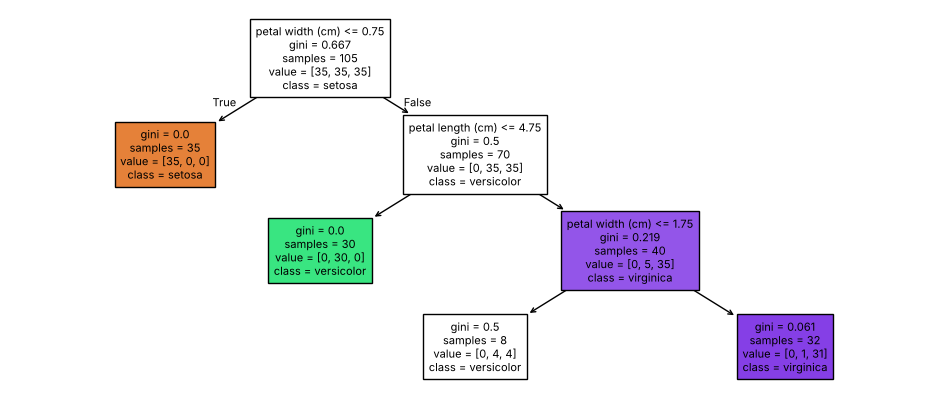

In [5]:
# 🔢 NumPy tree — same algorithm, but the split search is vectorised:
# sort once per feature, then cumulative class counts give the impurity of EVERY threshold at once.
class DecisionTreeNP:
    def __init__(self, max_depth=5, min_samples_leaf=1, max_features=None, seed=0):
        self.max_depth, self.min_leaf, self.max_features = max_depth, min_samples_leaf, max_features
        self.rng = np.random.default_rng(seed)

    def _best_split(self, X, y):
        n, d = X.shape
        best_gain, best = 0.0, None
        counts_total = np.bincount(y, minlength=self.K)
        parent = 1 - np.sum((counts_total / n) ** 2)
        feats = np.arange(d) if self.max_features is None else self.rng.choice(d, self.max_features, replace=False)
        for j in feats:
            order = np.argsort(X[:, j]); xs, ys = X[order, j], y[order]
            left_counts = np.cumsum(np.eye(self.K)[ys], axis=0)[:-1]         # class counts left of each cut
            right_counts = counts_total - left_counts
            nl = np.arange(1, n); nr = n - nl
            gini_l = 1 - np.sum((left_counts / nl[:, None]) ** 2, axis=1)
            gini_r = 1 - np.sum((right_counts / nr[:, None]) ** 2, axis=1)
            gain = parent - (nl * gini_l + nr * gini_r) / n
            valid = (xs[1:] != xs[:-1]) & (nl >= self.min_leaf) & (nr >= self.min_leaf)   # only cut between distinct values
            if valid.any():
                i = np.argmax(np.where(valid, gain, -1))
                if gain[i] > best_gain:
                    best_gain, best = gain[i], (j, (xs[i] + xs[i + 1]) / 2)
        return best, best_gain

    def _grow(self, X, y, depth):
        counts = np.bincount(y, minlength=self.K)
        if depth >= self.max_depth or counts.max() == len(y):
            return counts
        split, gain = self._best_split(X, y)
        if split is None:
            return counts
        j, t = split; m = X[:, j] < t
        self.importances[j] += gain * len(y)              # for feature importance (Section 6)
        return (j, t, self._grow(X[m], y[m], depth + 1), self._grow(X[~m], y[~m], depth + 1))

    def fit(self, X, y):
        self.K = y.max() + 1; self.importances = np.zeros(X.shape[1])
        self.root = self._grow(X, y, 0)
        self.importances /= max(self.importances.sum(), 1e-12)
        return self

    def _leaf(self, x):
        node = self.root
        while isinstance(node, tuple):
            j, t, l, r = node; node = l if x[j] < t else r
        return node

    def predict_proba(self, X):
        P = np.array([self._leaf(x) for x in X], float)
        return P / P.sum(1, keepdims=True)

    def predict(self, X):
        return self.predict_proba(X).argmax(1)

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
Xtr, Xte, ytr, yte = train_test_split(Xi, yi, test_size=0.3, random_state=1, stratify=yi)
py_acc = np.mean([predict_tree_python(build_tree_python(Xtr.tolist(), ytr.tolist(), max_depth=3), x) for x in Xte.tolist()] == yte)
print(f"pure Python tree test acc: {py_acc:.3f}")
print("(when two splits tie on gain, implementations may pick different ones — so small differences are normal)")
print(f"NumPy tree test acc:       {np.mean(DecisionTreeNP(max_depth=3).fit(Xtr, ytr).predict(Xte) == yte):.3f}")
sk_tree = DecisionTreeClassifier(max_depth=3, random_state=0).fit(Xtr, ytr)
print(f"sklearn tree test acc:     {sk_tree.score(Xte, yte):.3f}")

plt.figure(figsize=(12, 5))
plot_tree(sk_tree, feature_names=iris.feature_names, class_names=iris.target_names, filled=True, fontsize=8); plt.show()

## 4. Trees overfit — and how to stop them

Left alone, a tree keeps splitting until every leaf is pure, memorising every noisy point. Controls (**pre-pruning**):
- `max_depth` — limit the number of questions in a row
- `min_samples_leaf` — each leaf must contain at least this many samples
- `min_impurity_decrease`, `max_leaf_nodes`

Or grow fully and **prune back** (`ccp_alpha` in sklearn — cost-complexity pruning).

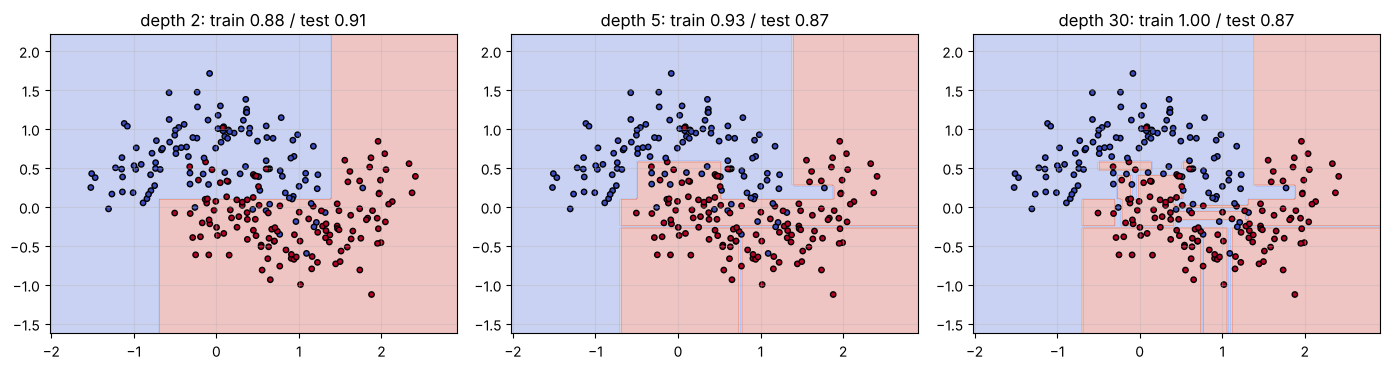

In [6]:
from sklearn.datasets import make_moons
Xm, ym = make_moons(400, noise=0.3, random_state=0)
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(Xm, ym, test_size=0.4, random_state=0)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, depth in zip(axes, [2, 5, 30]):
    t = DecisionTreeNP(max_depth=depth).fit(Xm_tr, ym_tr)
    plot_boundary(t.predict, Xm_tr, ym_tr, ax,
                  f"depth {depth}: train {np.mean(t.predict(Xm_tr) == ym_tr):.2f} / test {np.mean(t.predict(Xm_te) == ym_te):.2f}")
plt.tight_layout(); plt.show()

Trees are **high-variance** models: change a few training points and the whole tree can change. The ensemble methods below exploit exactly this.

## 5. Bagging and Random Forests — wisdom of crowds

**Bagging** (Bootstrap AGGregatING):
1. Create B new training sets by sampling n rows **with replacement** (a *bootstrap sample* — some rows appear twice, ~37% don't appear at all).
2. Train a deep tree on each.
3. Average their predictions (vote for classification).

Each tree overfits differently; averaging cancels much of the noise. Averaging B models with variance σ² and correlation ρ gives variance $\rho\sigma^2 + \frac{1-\rho}{B}\sigma^2$ — so **the less correlated the trees, the better.**

**Random Forest** = bagging + a twist: at every split, each tree may only consider a **random subset of features** (typically √d). This de-correlates the trees further — no single strong feature dominates every tree.

**Bonus — out-of-bag (OOB) score:** each tree never saw ~37% of rows; evaluating on those gives a free validation score.

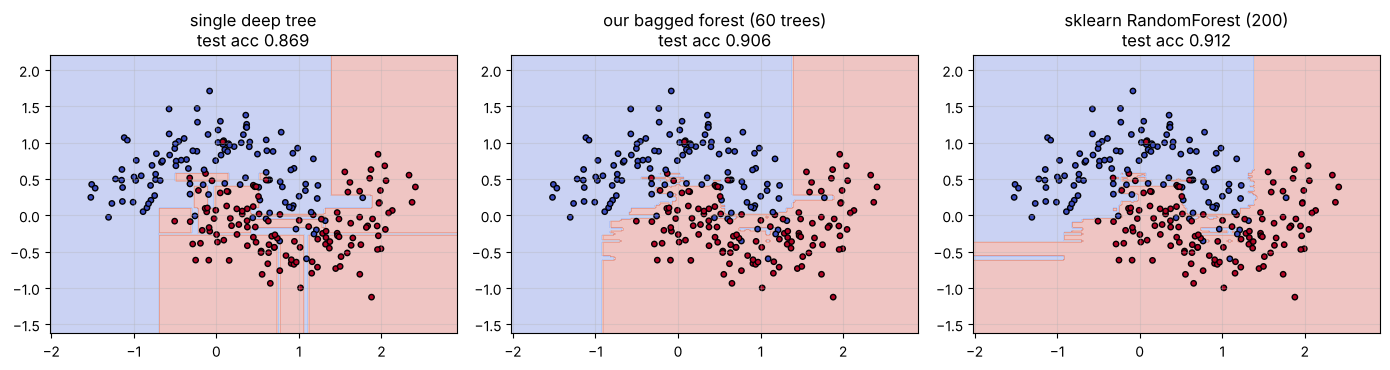

In [7]:
# 🔢 Random Forest built from our own NumPy trees
class RandomForestNP:
    def __init__(self, n_trees=50, max_depth=10, max_features="sqrt", seed=0):
        self.n_trees, self.max_depth, self.max_features, self.seed = n_trees, max_depth, max_features, seed
    def fit(self, X, y):
        n, d = X.shape; rng = np.random.default_rng(self.seed)
        mf = int(np.sqrt(d)) if self.max_features == "sqrt" else self.max_features
        self.trees = []
        for b in range(self.n_trees):
            idx = rng.integers(0, n, n)                                 # bootstrap sample (with replacement)
            self.trees.append(DecisionTreeNP(self.max_depth, max_features=mf, seed=b).fit(X[idx], y[idx]))
        return self
    def predict_proba(self, X):
        return np.mean([t.predict_proba(X) for t in self.trees], axis=0)   # average the trees' votes
    def predict(self, X):
        return self.predict_proba(X).argmax(1)

from sklearn.ensemble import RandomForestClassifier
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
single = DecisionTreeNP(max_depth=30).fit(Xm_tr, ym_tr)
rf_np = RandomForestNP(n_trees=60, max_features=2).fit(Xm_tr, ym_tr)   # 2 features only → use both (bagging)
rf_sk = RandomForestClassifier(n_estimators=200, random_state=0).fit(Xm_tr, ym_tr)
for ax, (name, m) in zip(axes, [("single deep tree", single), ("our bagged forest (60 trees)", rf_np), ("sklearn RandomForest (200)", rf_sk)]):
    plot_boundary(m.predict, Xm_tr, ym_tr, ax, f"{name}\ntest acc {np.mean(m.predict(Xm_te) == ym_te):.3f}")
plt.tight_layout(); plt.show()

In [8]:
# Bootstrap facts, checked: a bootstrap sample contains ~63.2% of the unique rows (1 − 1/e)
n = 10_000
print("fraction of unique rows in a bootstrap sample:", len(np.unique(rng.integers(0, n, n))) / n, " (theory 1 − 1/e =", round(1 - 1 / math.e, 3), ")")

fraction of unique rows in a bootstrap sample: 0.635  (theory 1 − 1/e = 0.632 )


## 6. Feature importance

**Impurity importance** (what `feature_importances_` returns): total impurity reduction contributed by splits on each feature. Fast, but biased toward features with many unique values.

**Permutation importance:** shuffle one feature's column in the validation set and measure how much the score drops. Slower but more trustworthy.

our forest test acc: 0.930   sklearn forest: 0.953


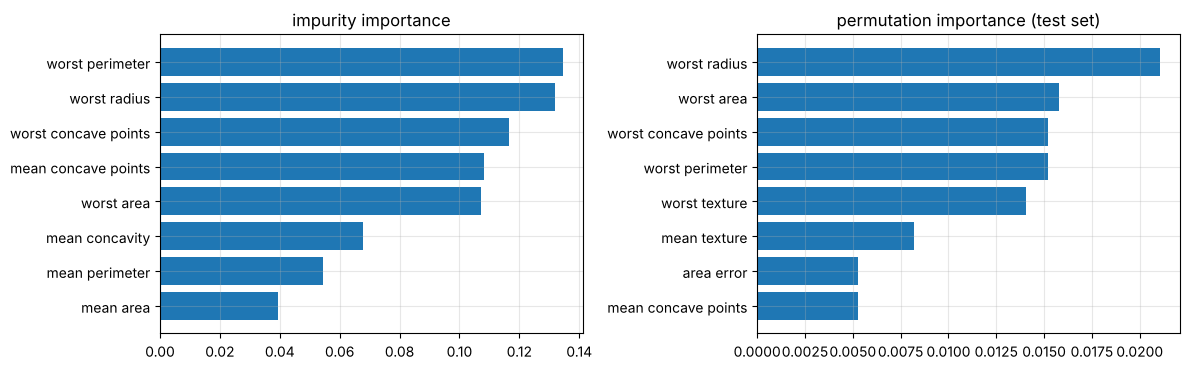

In [9]:
from sklearn.datasets import load_breast_cancer
from sklearn.inspection import permutation_importance
bc = load_breast_cancer()
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(bc.data, bc.target, test_size=0.3, random_state=0, stratify=bc.target)

rf = RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1).fit(Xb_tr, yb_tr)
ours = RandomForestNP(n_trees=40, max_depth=8).fit(Xb_tr, yb_tr)
print(f"our forest test acc: {np.mean(ours.predict(Xb_te) == yb_te):.3f}   sklearn forest: {rf.score(Xb_te, yb_te):.3f}")

perm = permutation_importance(rf, Xb_te, yb_te, n_repeats=10, random_state=0)
top = np.argsort(rf.feature_importances_)[-8:]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].barh(bc.feature_names[top], rf.feature_importances_[top]); ax[0].set_title("impurity importance")
top_p = np.argsort(perm.importances_mean)[-8:]
ax[1].barh(bc.feature_names[top_p], perm.importances_mean[top_p]); ax[1].set_title("permutation importance (test set)")
plt.tight_layout(); plt.show()

## 7. Boosting — learning from mistakes

Bagging trains trees **independently, in parallel**, to reduce **variance**. Boosting trains **small, weak** trees **one after another**, each focusing on what the previous ones got wrong — reducing **bias**.

### 7.1 AdaBoost (the original)
1. Give every sample equal weight.
2. Train a tiny tree (a "stump": one split) on the weighted data.
3. Compute its weighted error ε and its say $\alpha = \frac{1}{2}\ln\frac{1-\varepsilon}{\varepsilon}$ (accurate stumps get more say).
4. **Increase the weights of misclassified samples**, so the next stump focuses on them.
5. Final prediction: weighted vote $\text{sign}(\sum_m \alpha_m h_m(x))$.

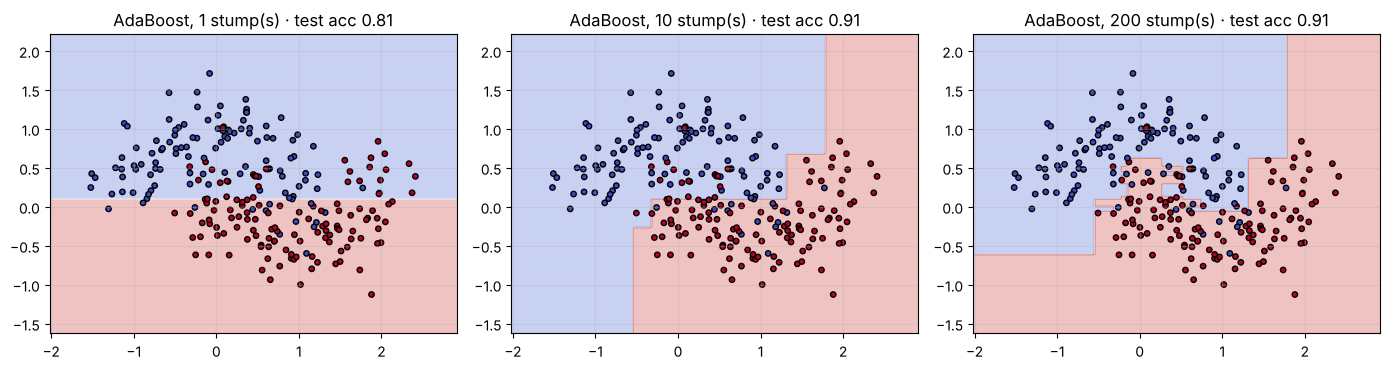

In [10]:
# 🔢 AdaBoost from scratch (labels −1/+1), using sklearn stumps as the weak learner
class AdaBoostNP:
    def __init__(self, n_rounds=50):
        self.n_rounds = n_rounds
    def fit(self, X, y):
        n = len(y); w = np.full(n, 1 / n)
        self.stumps, self.alphas = [], []
        for _ in range(self.n_rounds):
            stump = DecisionTreeClassifier(max_depth=1).fit(X, y, sample_weight=w)
            pred = stump.predict(X)
            err = np.clip(w[pred != y].sum(), 1e-10, 1 - 1e-10)
            alpha = 0.5 * np.log((1 - err) / err)
            w *= np.exp(-alpha * y * pred)            # wrong → y·pred = −1 → weight grows by e^α
            w /= w.sum()
            self.stumps.append(stump); self.alphas.append(alpha)
        return self
    def decision_function(self, X):
        return sum(a * s.predict(X) for a, s in zip(self.alphas, self.stumps))
    def predict(self, X):
        return np.sign(self.decision_function(X))

ym_pm = np.where(ym_tr == 1, 1, -1)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, rounds in zip(axes, [1, 10, 200]):
    ab = AdaBoostNP(rounds).fit(Xm_tr, ym_pm)
    acc = np.mean(ab.predict(Xm_te) == np.where(ym_te == 1, 1, -1))
    plot_boundary(ab.predict, Xm_tr, ym_tr, ax, f"AdaBoost, {rounds} stump(s) · test acc {acc:.2f}")
plt.tight_layout(); plt.show()

### 7.2 Gradient Boosting — the idea behind XGBoost & LightGBM

For regression with squared loss, the idea is beautifully simple:
1. Start with a constant prediction $F_0(x) = \bar{y}$.
2. Compute the **residuals** $r_i = y_i - F(x_i)$ — what we still get wrong.
3. Fit a small tree $h$ to the residuals.
4. Update $F(x) \leftarrow F(x) + \eta \cdot h(x)$ — η (learning rate, e.g. 0.1) takes a *small* step.
5. Repeat.

Why "gradient"? The residual $y - F$ is exactly the **negative gradient** of the squared loss $\frac{1}{2}(y-F)^2$ with respect to the prediction F. So each tree is a step of **gradient descent in function space**. Swap in another loss (log-loss for classification, absolute error, ranking losses…) and you fit trees to *its* negative gradient instead — that's the general algorithm.

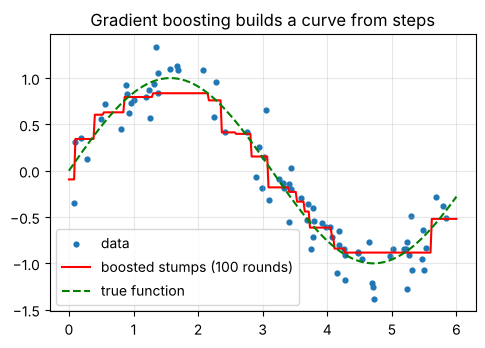

In [11]:
# 🐍 Pure Python gradient boosting with one-split "stumps" (1 feature, regression)
def fit_stump_python(xs, rs):
    """Best single threshold for predicting residuals rs from xs (minimise squared error)."""
    best = None
    pairs = sorted(zip(xs, rs))
    for i in range(1, len(pairs)):
        t = (pairs[i - 1][0] + pairs[i][0]) / 2
        left = [r for x, r in pairs if x < t]; right = [r for x, r in pairs if x >= t]
        lm, rm = sum(left) / len(left), sum(right) / len(right)
        sse = sum((r - lm) ** 2 for r in left) + sum((r - rm) ** 2 for r in right)
        if best is None or sse < best[0]:
            best = (sse, t, lm, rm)
    _, t, lm, rm = best
    return lambda x: lm if x < t else rm

def gradient_boost_python(xs, ys, n_rounds=100, lr=0.1):
    f0 = sum(ys) / len(ys)
    preds = [f0] * len(ys); stumps = []
    for _ in range(n_rounds):
        residuals = [y - p for y, p in zip(ys, preds)]        # = negative gradient of squared loss
        h = fit_stump_python(xs, residuals)
        stumps.append(h)
        preds = [p + lr * h(x) for p, x in zip(preds, xs)]
    return lambda x: f0 + lr * sum(h(x) for h in stumps)

xr = np.sort(rng.uniform(0, 6, 80)); yr = np.sin(xr) + rng.normal(0, 0.2, 80)
gb_py = gradient_boost_python(xr.tolist(), yr.tolist(), n_rounds=100)
grid = np.linspace(0, 6, 300)
plt.scatter(xr, yr, s=12, label="data"); plt.plot(grid, [gb_py(g) for g in grid], "r", label="boosted stumps (100 rounds)")
plt.plot(grid, np.sin(grid), "g--", label="true function"); plt.legend(); plt.title("Gradient boosting builds a curve from steps"); plt.show()

our GB test RMSE: 64.08   sklearn GB test RMSE: 64.21
best number of rounds on test: 25 (in practice choose this with a VALIDATION set → 'early stopping')


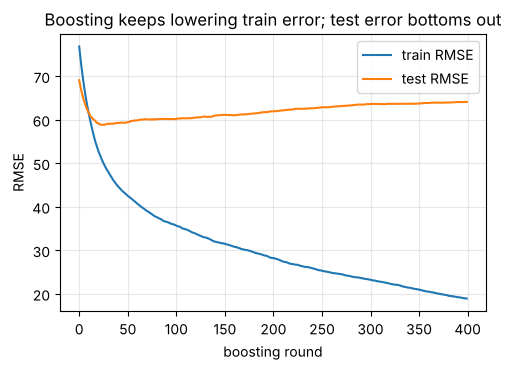

In [12]:
# 🔢 NumPy/sklearn-tree gradient boosting for multi-feature regression — watch it improve round by round
from sklearn.tree import DecisionTreeRegressor
from sklearn.datasets import load_diabetes
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error

class GradientBoostingRegressorNP:
    def __init__(self, n_rounds=200, lr=0.05, max_depth=3):
        self.n_rounds, self.lr, self.max_depth = n_rounds, lr, max_depth
    def fit(self, X, y):
        self.f0 = y.mean(); F = np.full(len(y), self.f0); self.trees = []
        for _ in range(self.n_rounds):
            tree = DecisionTreeRegressor(max_depth=self.max_depth).fit(X, y - F)   # fit the residuals
            F += self.lr * tree.predict(X); self.trees.append(tree)
        return self
    def staged_predict(self, X):
        F = np.full(len(X), self.f0)
        for t in self.trees:
            F = F + self.lr * t.predict(X); yield F
    def predict(self, X):
        return list(self.staged_predict(X))[-1]

Xd, yd = load_diabetes(return_X_y=True)
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(Xd, yd, test_size=0.25, random_state=0)
gb = GradientBoostingRegressorNP(n_rounds=400).fit(Xd_tr, yd_tr)
sk_gb = GradientBoostingRegressor(n_estimators=400, learning_rate=0.05, max_depth=3, random_state=0).fit(Xd_tr, yd_tr)
tr_curve = [mean_squared_error(yd_tr, p) ** .5 for p in gb.staged_predict(Xd_tr)]
te_curve = [mean_squared_error(yd_te, p) ** .5 for p in gb.staged_predict(Xd_te)]
print(f"our GB test RMSE: {te_curve[-1]:.2f}   sklearn GB test RMSE: {mean_squared_error(yd_te, sk_gb.predict(Xd_te)) ** .5:.2f}")
print(f"best number of rounds on test: {np.argmin(te_curve) + 1} (in practice choose this with a VALIDATION set → 'early stopping')")
plt.plot(tr_curve, label="train RMSE"); plt.plot(te_curve, label="test RMSE")
plt.xlabel("boosting round"); plt.ylabel("RMSE"); plt.legend(); plt.title("Boosting keeps lowering train error; test error bottoms out"); plt.show()

### 7.3 Modern gradient boosting libraries

| Library | Key ideas |
|---|---|
| **XGBoost** | uses 2nd-order (Newton) gradients, explicit regularisation of leaf values, sparsity-aware splits |
| **LightGBM** | histogram binning of features (very fast), leaf-wise tree growth |
| **CatBoost** | excellent native handling of categorical features, ordered boosting to reduce leakage |
| **sklearn `HistGradientBoosting*`** | LightGBM-style, built into scikit-learn |

The hyperparameters that matter most: **learning rate** × **number of trees** (lower lr needs more trees — use early stopping), **tree depth / num_leaves**, **subsampling** of rows and columns, and **min samples per leaf**.

In [13]:
from sklearn.ensemble import HistGradientBoostingClassifier, AdaBoostClassifier
from sklearn.model_selection import cross_val_score
models = {
    "single tree (depth 4)": DecisionTreeClassifier(max_depth=4, random_state=0),
    "random forest": RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1),
    "AdaBoost": AdaBoostClassifier(n_estimators=200, random_state=0),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=0),
}
for name, m in models.items():
    s = cross_val_score(m, bc.data, bc.target, cv=5)
    print(f"{name:24s} accuracy {s.mean():.3f} ± {s.std():.3f}")

single tree (depth 4)    accuracy 0.916 ± 0.019


random forest            accuracy 0.963 ± 0.022


AdaBoost                 accuracy 0.977 ± 0.009


HistGradientBoosting     accuracy 0.965 ± 0.018


## 8. Bagging vs Boosting — summary

| | Bagging / Random Forest | Boosting (AdaBoost, GBM) |
|---|---|---|
| Trees trained | independently (parallel) | sequentially, each fixing the last |
| Tree size | deep (low bias, high variance) | shallow (high bias, low variance) |
| Mainly reduces | **variance** | **bias** |
| Overfits with more trees? | no — more trees just stabilises | yes, eventually — use early stopping |
| Tuning effort | low — great default | higher, usually more accurate |

## 9. Key takeaways
- Trees pick splits greedily by maximising impurity reduction (Gini/entropy for classification, variance for regression).
- A single deep tree overfits; limit depth/leaf size or use an ensemble.
- **Random Forest** = bootstrap samples + random feature subsets + averaging.
- **Gradient boosting** = add small trees fitted to the negative gradient (residuals), with a small learning rate.

## 10. Exercises
1. Modify `best_split_python` to use **variance** as the impurity, turning the tree into a **regression tree**. Test on `xr, yr`.
2. Add an **OOB score** to `RandomForestNP`: for each row, average only the trees whose bootstrap sample didn't contain it.
3. In `GradientBoostingRegressorNP`, try `lr=0.5` and `lr=0.01`. How does the best number of rounds change?

In [14]:
# Exercise 1 — solution: a regression tree just swaps the impurity function
def variance_impurity(values):
    m = sum(values) / len(values)
    return sum((v - m) ** 2 for v in values) / len(values)

s = best_split_python([[x] for x in xr.tolist()], yr.tolist(), criterion=variance_impurity)
print(f"best first regression split at x = {s['threshold']:.2f}  (sin changes sign at π ≈ 3.14)")

best first regression split at x = 3.08  (sin changes sign at π ≈ 3.14)


**Next:** [06 · Unsupervised Learning](06_unsupervised_learning.ipynb) — clustering and dimensionality reduction, when there are no labels at all.

*Going deeper / interview prep:* `ML_Interview_Notes.md` §3.7–3.8 · `Probability_Statistics_Notes.md` §3.4 (bootstrap) · code: `ml_from_scratch.py` → `DecisionTree`, `RandomForest`, `AdaBoost`, `GradientBoostingRegressor` · `ml_from_scratch_part2.py` → `XGBoostStyleBooster`, `ExtraTrees`, `StackingEnsemble`.